<a href="https://colab.research.google.com/github/luchytv-png/Laboratorios-estadisitca/blob/main/Laboratorio_11_azul.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="background:linear-gradient(135deg,#0b1f4d,#1d4ed8 60%,#3b82f6);color:#fff;padding:40px 20px;border-radius:16px;text-align:center">
<div style="letter-spacing:3px;font-size:13px">LABORATORIO 11 · ESTADÍSTICA</div>
<div style="font-size:36px;font-weight:bold;margin:10px 0">Ley de los grandes números</div>
<div style="opacity:.9">Probabilidad con simulaciones en Python</div>
<div style="display:inline-block;margin-top:16px;padding:8px 18px;border-radius:30px;background:rgba(255,255,255,.18);border:1px solid rgba(255,255,255,.4)"><b>Luis Antonio Tamara Velasquez</b> · luchytv@gmail.com</div>
</div>

In [1]:
NOMBRE = "Luis Antonio Tamara"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

# Paleta azul
AZUL_OSC, AZUL, AZUL_MED, AZUL_CLA = "#0b1f4d", "#1d4ed8", "#3b82f6", "#bfdbfe"
plt.rcParams.update({
    "axes.edgecolor": AZUL_OSC, "axes.labelcolor": AZUL_OSC, "axes.titlecolor": AZUL_OSC,
    "axes.titleweight": "bold", "axes.facecolor": "#f8fbff", "xtick.color": AZUL_OSC,
    "ytick.color": AZUL_OSC, "grid.color": "#dbeafe", "axes.grid": True, "figure.facecolor": "white"})

def firma(ax):
    """Inserta el nombre dentro del gráfico."""
    ax.text(0.98, 0.02, NOMBRE, transform=ax.transAxes, ha="right", va="bottom", fontsize=10,
            color=AZUL, bbox=dict(facecolor="white", alpha=0.9, edgecolor=AZUL))

<div style="background:linear-gradient(90deg,#0b1f4d,#1d4ed8);color:#fff;padding:14px 20px;border-radius:12px;font-size:20px;font-weight:bold">1 &nbsp; Ley de los grandes números</div>

Si repetimos un experimento aleatorio muchas veces y de forma independiente, la frecuencia relativa de un evento se acerca a su probabilidad real.

### 1.1 Moneda justa (p = 1/2)

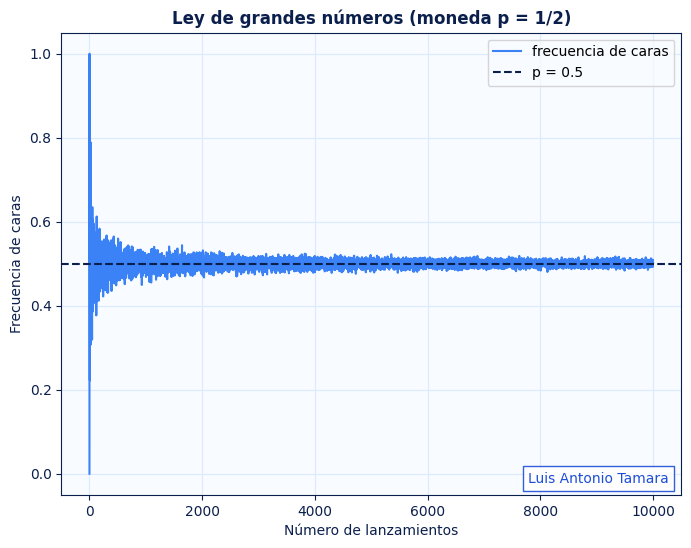

Frecuencia final de caras: 0.5017


In [2]:
resultados = []
for n in range(1, 10000):
    lanzamientos = np.random.choice([0, 1], n)      # cara=1, sello=0
    resultados.append(lanzamientos.mean())

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(resultados, color=AZUL_MED, label="frecuencia de caras")
ax.axhline(0.5, color=AZUL_OSC, linestyle="--", label="p = 0.5")
ax.set_title("Ley de grandes números (moneda p = 1/2)")
ax.set_xlabel("Número de lanzamientos")
ax.set_ylabel("Frecuencia de caras")
ax.legend()
firma(ax)
plt.show()
print("Frecuencia final de caras:", round(resultados[-1], 4))

### 1.2 Moneda cargada (p = 1/6)

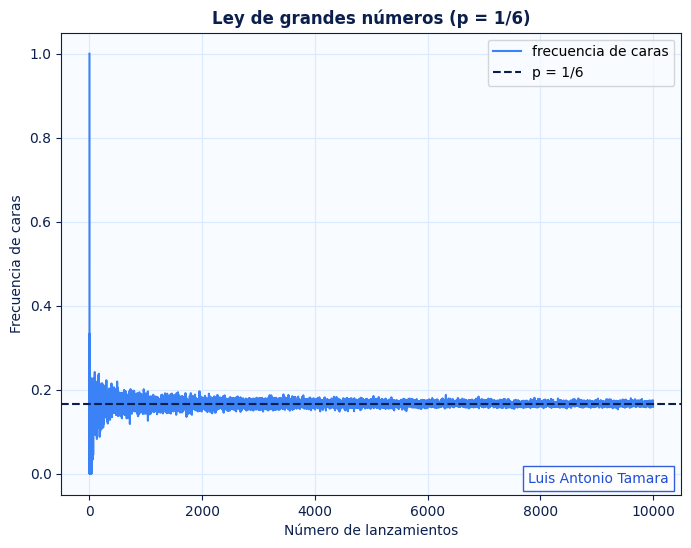

Frecuencia final de caras: 0.1668 | 1/6 = 0.1667


In [3]:
resultados = []
for n in range(1, 10000):
    lanzamientos = np.random.choice([0, 1], n, p=[5/6, 1/6])
    resultados.append(lanzamientos.mean())

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(resultados, color=AZUL_MED, label="frecuencia de caras")
ax.axhline(1/6, color=AZUL_OSC, linestyle="--", label="p = 1/6")
ax.set_title("Ley de grandes números (p = 1/6)")
ax.set_xlabel("Número de lanzamientos")
ax.set_ylabel("Frecuencia de caras")
ax.legend()
firma(ax)
plt.show()
print("Frecuencia final de caras:", round(resultados[-1], 4), "| 1/6 =", round(1/6, 4))

<div style="background:#dbeafe;color:#1e293b;border-left:6px solid #1d4ed8;padding:12px 16px;border-radius:8px"><b>Interpretación:</b> al inicio la frecuencia oscila mucho, pero conforme aumentan los lanzamientos se estabiliza en la probabilidad real (0.5 en el primer caso y 1/6 ≈ 0.167 en el segundo).</div>

<div style="background:linear-gradient(90deg,#0b1f4d,#1d4ed8);color:#fff;padding:14px 20px;border-radius:12px;font-size:20px;font-weight:bold">2 &nbsp; Teorema del límite central</div>

La distribución de las **medias muestrales** de variables independientes tiende a una distribución normal, sin importar la distribución original. Lo comprobamos con cuatro distribuciones: binomial, Poisson, geométrica y exponencial.

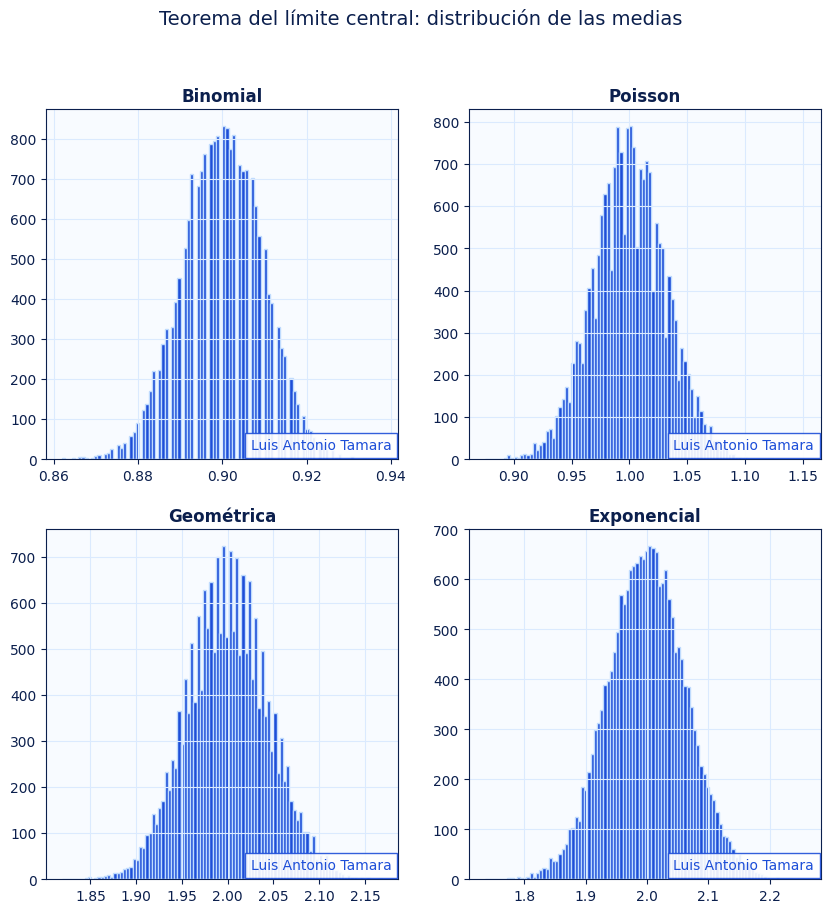

In [4]:
n_rep = 20000     # número de muestras
size = 1000       # tamaño de cada muestra

medias = {
    "Binomial":    np.random.binomial(1, 0.9, size=(n_rep, size)).mean(axis=1),
    "Poisson":     np.random.poisson(lam=1.0, size=(n_rep, size)).mean(axis=1),
    "Geométrica":  np.random.geometric(p=0.5, size=(n_rep, size)).mean(axis=1),
    "Exponencial": np.random.exponential(scale=2.0, size=(n_rep, size)).mean(axis=1),
}

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10))
for ax, (nombre, datos) in zip(axes.ravel(), medias.items()):
    ax.hist(datos, bins=100, color=AZUL, edgecolor=AZUL_CLA)
    ax.set_title(nombre)
    firma(ax)
fig.suptitle("Teorema del límite central: distribución de las medias", fontsize=14, color=AZUL_OSC)
plt.show()

<div style="background:#dbeafe;color:#1e293b;border-left:6px solid #1d4ed8;padding:12px 16px;border-radius:8px"><b>Interpretación:</b> las cuatro distribuciones, que son muy distintas entre sí, producen medias con la forma de campana de la distribución normal.</div>

<div style="background:linear-gradient(90deg,#0b1f4d,#1d4ed8);color:#fff;padding:14px 20px;border-radius:12px;font-size:20px;font-weight:bold">3 &nbsp; Situación 1 – La coincidencia de cumpleaños</div>

En una fiesta hay **100 personas**. Un amigo apuesta $100 a que al menos dos personas cumplen años el mismo día. Si él gana, le pagamos $100; si pierde, nos paga $100. **¿Deberíamos aceptar la apuesta?**

P(al menos dos comparten cumpleaños) con 100 personas = 0.9999996928
P(nadie comparte) = 3.07e-07


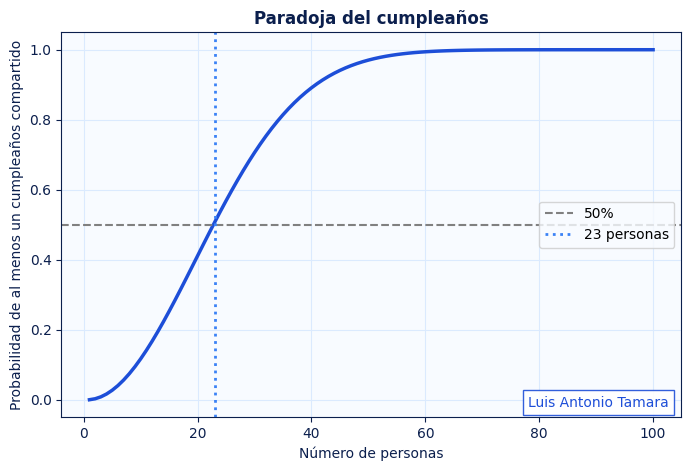

Simulación (20000 fiestas): 1.0000


In [5]:
def prob_cumple_compartido(n):
    p_ninguno = 1.0
    for i in range(n):
        p_ninguno *= (365 - i) / 365
    return 1 - p_ninguno

asistentes = 100
print(f"P(al menos dos comparten cumpleaños) con {asistentes} personas = {prob_cumple_compartido(asistentes):.10f}")
print(f"P(nadie comparte) = {1 - prob_cumple_compartido(asistentes):.2e}")

ns = range(1, 101)
ps = [prob_cumple_compartido(n) for n in ns]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ns, ps, color=AZUL, linewidth=2.5)
ax.axhline(0.5, color="gray", linestyle="--", label="50%")
ax.axvline(23, color=AZUL_MED, linestyle=":", linewidth=2, label="23 personas")
ax.set_title("Paradoja del cumpleaños")
ax.set_xlabel("Número de personas")
ax.set_ylabel("Probabilidad de al menos un cumpleaños compartido")
ax.legend(loc="center right")
firma(ax)
plt.show()

sim = 20000
exitos = sum(len(set(np.random.randint(0, 365, asistentes))) < asistentes for _ in range(sim))
print(f"Simulación ({sim} fiestas): {exitos/sim:.4f}")

### Explicación de la solución

Calcular directamente la probabilidad de que *al menos dos* coincidan es complicado, así que se calcula el **complemento**: la probabilidad de que **nadie** coincida. La primera persona tiene 365/365 de no coincidir con nadie, la segunda 364/365, la tercera 363/365, y así sucesivamente. Como los eventos se encadenan, se multiplican:

P(nadie coincide) = (365/365)·(364/365)·(363/365)···(266/365)

y entonces P(al menos dos coinciden) = 1 − P(nadie coincide).

Con 100 personas, P(nadie coincide) es casi cero (del orden de 3·10⁻⁷), por lo que la probabilidad de coincidencia es prácticamente 1 (99,99997 %). Con apenas 23 personas ya supera el 50 %.

<div style="background:#0b1f4d;color:#fff;border-left:6px solid #0b1f4d;padding:12px 16px;border-radius:8px"><b>Conclusión:</b> no deberíamos aceptar la apuesta. Nuestro amigo tiene casi la victoria asegurada; la intuición nos engaña porque pensamos en 365 días y 100 personas, pero lo que cuenta son las <b>miles de parejas posibles</b> (100·99/2 = 4950).</div>

<div style="background:linear-gradient(90deg,#0b1f4d,#1d4ed8);color:#fff;padding:14px 20px;border-radius:12px;font-size:20px;font-weight:bold">4 &nbsp; Situación 2 – El problema de Monty Hall</div>

Hay tres puertas: detrás de una hay un carro y detrás de las otras dos, cabras. Elegimos una puerta; el presentador (que sabe dónde está el carro) abre otra puerta con una cabra y nos ofrece cambiar. **¿Debemos cambiar o mantener la elección?**

10,000 concursos sin cambiar de puerta:
  gana: 3359 | pierde: 6641 | victorias: 33.59%

10,000 concursos cambiando de puerta:
  gana: 6568 | pierde: 3432 | victorias: 65.68%



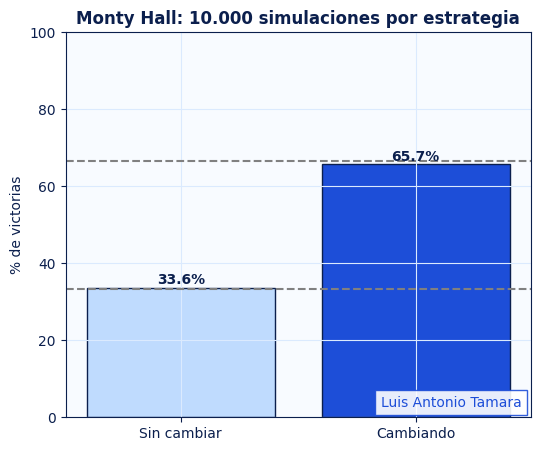

In [6]:
class MontyHall:
    def __init__(self):
        self.puertas = [0, 1, 2]
        self.premio = random.choice(self.puertas)      # puerta con el carro
        self.eleccion = random.choice(self.puertas)    # elección inicial

    def jugar(self, cambiar):
        # El presentador abre una puerta que no es la elegida ni la del premio
        opciones = [p for p in self.puertas if p != self.eleccion and p != self.premio]
        abierta = random.choice(opciones)
        if cambiar:
            self.eleccion = [p for p in self.puertas if p != self.eleccion and p != abierta][0]
        return self.eleccion == self.premio

N = 10000
resumen = {}
for estrategia, cambiar in [("Sin cambiar", False), ("Cambiando", True)]:
    gana = sum(MontyHall().jugar(cambiar) for _ in range(N))
    resumen[estrategia] = 100 * gana / N
    print(f"{N:,} concursos {estrategia.lower()} de puerta:")
    print(f"  gana: {gana} | pierde: {N-gana} | victorias: {100*gana/N:.2f}%\n")

fig, ax = plt.subplots(figsize=(6, 5))
barras = ax.bar(resumen.keys(), resumen.values(), color=[AZUL_CLA, AZUL], edgecolor=AZUL_OSC)
ax.axhline(100/3, color="gray", linestyle="--")
ax.axhline(200/3, color="gray", linestyle="--")
ax.set_ylabel("% de victorias")
ax.set_title("Monty Hall: 10.000 simulaciones por estrategia")
ax.set_ylim(0, 100)
for b in barras:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1, f"{b.get_height():.1f}%", ha="center", color=AZUL_OSC, fontweight="bold")
firma(ax)
plt.show()

### Explicación de la solución

Al elegir al inicio, la probabilidad de acertar la puerta del carro es **1/3**, y la de que esté en alguna de las otras dos es **2/3**. El presentador no abre una puerta al azar: **sabe** dónde está el carro y siempre abre una puerta con cabra. Por eso, su acción no cambia la probabilidad de nuestra primera elección (sigue siendo 1/3), pero concentra toda la probabilidad restante (2/3) en la puerta que queda cerrada.

- Si **mantenemos** la puerta: ganamos solo si acertamos de entrada → 1/3.
- Si **cambiamos**: ganamos siempre que nuestra primera elección haya sido una cabra → 2/3.

La simulación lo confirma: ≈ 33 % sin cambiar y ≈ 66 % cambiando.

<div style="background:#0b1f4d;color:#fff;border-left:6px solid #0b1f4d;padding:12px 16px;border-radius:8px"><b>Conclusión:</b> debemos cambiar de puerta, porque duplica nuestras probabilidades de ganar el carro.</div>